# Baseline models

This notebook compares logistic regression, random forest and histogram-based gradient boosting for illicit Bitcoin transaction detection. All evaluations use chronological splits: models train on earlier time steps and predict later ones.

The main holdout uses steps 1–29 for training and 30–35 for validation. Three walk-forward windows are used to check whether performance is consistent across time. ROC-AUC and average precision are reported; confusion matrices use a 0.5 threshold.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay
)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

train = pd.read_csv(PROJECT_ROOT / "data/raw/train.csv")

TARGET = "label"
ID_COL = "txId"
TIME_COL = "time_step"

feature_cols = [
    col for col in train.columns
    if col not in [ID_COL, TIME_COL, TARGET]
]

labelled = train[train[TARGET].notna()].copy()

train_df = labelled[labelled[TIME_COL] <= 29].copy()
val_df = labelled[
    labelled[TIME_COL].between(30, 35)
].copy()

X_train = train_df[feature_cols]
y_train = train_df[TARGET].astype(int)

X_val = val_df[feature_cols]
y_val = val_df[TARGET].astype(int)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Training illicit rate:", y_train.mean())
print("Validation illicit rate:", y_val.mean())

Training: (26381, 165)
Validation: (4854, 165)
Training illicit rate: 0.10882832341457867
Validation illicit rate: 0.1592501030078286


In [8]:
lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

val_probs = lr_pipeline.predict_proba(X_val)[:, 1]

print("ROC-AUC:", roc_auc_score(y_val, val_probs))
print("PR-AUC:", average_precision_score(y_val, val_probs))

ROC-AUC: 0.9268753409689239
PR-AUC: 0.6545832735940013


              precision    recall  f1-score   support

           0       0.96      0.85      0.90      4081
           1       0.51      0.83      0.63       773

    accuracy                           0.84      4854
   macro avg       0.73      0.84      0.76      4854
weighted avg       0.89      0.84      0.86      4854



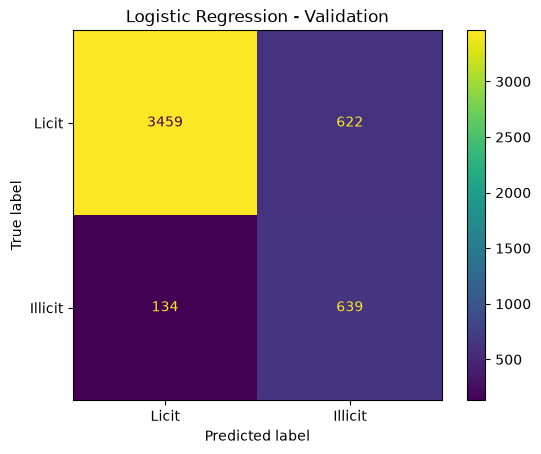

In [9]:
print(classification_report(
    y_val,
    (val_probs >= 0.5).astype(int),
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    (val_probs >= 0.5).astype(int),
    display_labels=["Licit", "Illicit"]
)

plt.title("Logistic Regression - Validation")
plt.show()

## Logistic regression and class weighting

The first comparison used logistic regression on transactions from time steps 1–29, with steps 30–35 held out for validation. Both versions used median imputation and standardisation.

Without class weighting, ROC-AUC increased from 0.9154 to 0.9269 and average precision from 0.5799 to 0.6546. False positives fell from 1,477 to 622, while false negatives rose from 14 to 134. Weighting therefore improved recall at the 0.5 threshold, but worsened the ranking metrics. The unweighted model was retained as the logistic regression baseline.

## Random forest

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

rf_probs = rf_pipeline.predict_proba(X_val)[:, 1]

print("Random Forest ROC-AUC:", roc_auc_score(y_val, rf_probs))
print("Random Forest PR-AUC:", average_precision_score(y_val, rf_probs))

Random Forest ROC-AUC: 0.9952393526559359
Random Forest PR-AUC: 0.9876031270633462


A random forest with 200 trees, maximum depth 15 and minimum leaf size 5 achieved 0.9952 ROC-AUC and 0.9876 average precision on steps 30–35. This was substantially better than logistic regression, suggesting that nonlinear relationships between the transaction features matter.

The next checks examine feature importance and performance across earlier validation windows. The strong result on one window alone is not enough to establish temporal robustness.

feat_53     0.052210
feat_47     0.049072
feat_90     0.045593
feat_55     0.042672
feat_14     0.037676
feat_43     0.035001
feat_18     0.033665
feat_41     0.032920
feat_5      0.031439
feat_132    0.029989
feat_49     0.025111
feat_163    0.021801
feat_142    0.019205
feat_138    0.019168
feat_46     0.019144
feat_76     0.018540
feat_52     0.017774
feat_2      0.017476
feat_161    0.014184
feat_23     0.013324
dtype: float64

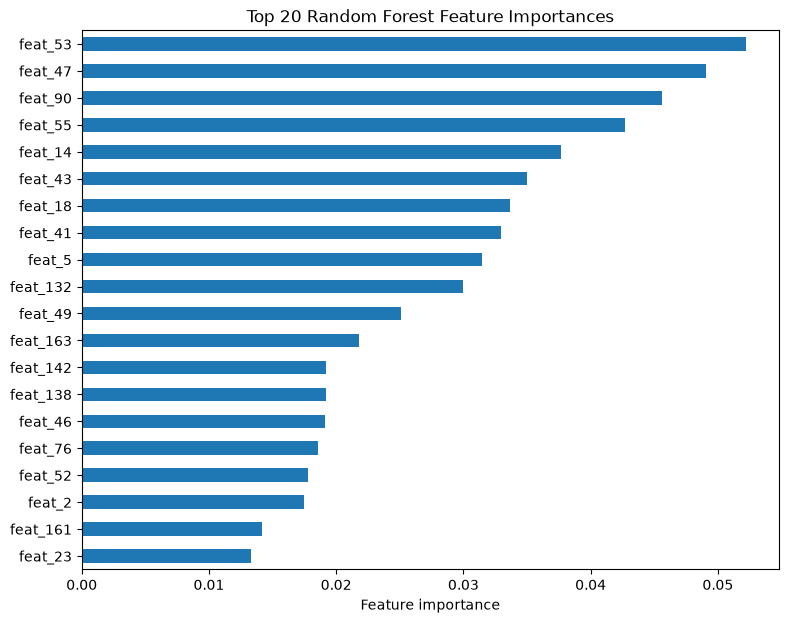

In [12]:
# Inspect random forest feature importance
importances = pd.Series(
    rf_pipeline.named_steps["model"].feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

display(importances.head(20))

importances.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 7),
    title="Top 20 Random Forest Feature Importances"
)

plt.xlabel("Feature importance")
plt.show()

In [11]:
print("Latest training time:", train_df["time_step"].max())
print("Earliest validation time:", val_df["time_step"].min())

print(
    "Overlapping transaction IDs:",
    len(set(train_df["txId"]) & set(val_df["txId"]))
)

Latest training time: 29
Earliest validation time: 30
Overlapping transaction IDs: 0


In [13]:
# Walk-forward validation
from sklearn.base import clone

folds = [
    (19, 20, 24),
    (24, 25, 29),
    (29, 30, 35)
]

results = []

for train_end, val_start, val_end in folds:

    fold_train = labelled[
        labelled["time_step"] <= train_end
    ]

    fold_val = labelled[
        labelled["time_step"].between(
            val_start, val_end
        )
    ]

    X_tr = fold_train[feature_cols]
    y_tr = fold_train[TARGET].astype(int)

    X_va = fold_val[feature_cols]
    y_va = fold_val[TARGET].astype(int)

    model = clone(rf_pipeline)
    model.fit(X_tr, y_tr)

    probs = model.predict_proba(X_va)[:, 1]

    results.append({
        "train_end": train_end,
        "validation": f"{val_start}-{val_end}",
        "roc_auc": roc_auc_score(y_va, probs),
        "average_precision": average_precision_score(
            y_va, probs
        ),
        "illicit_rate": y_va.mean()
    })

cv_results = pd.DataFrame(results)

display(cv_results)

print(
    "Mean ROC-AUC:",
    cv_results["roc_auc"].mean()
)

,train_end,validation,roc_auc,average_precision,illicit_rate
0,19,20-24,0.890128,0.845679,0.126046
1,24,25-29,0.995867,0.989227,0.234955
2,29,30-35,0.995239,0.987603,0.159250


Mean ROC-AUC: 0.9604115708338202


### Random forest across time

The most influential features included `feat_53`, `feat_47` and `feat_90`, although importance was spread across several columns. Training and validation transactions had no overlapping transaction IDs.

Walk-forward ROC-AUC was 0.8901, 0.9959 and 0.9952 across the three windows (mean 0.9604). The much weaker first window shows that performance depends on the period and possibly on the amount of training data available.

## Histogram-based gradient boosting

The next model uses histogram-based gradient boosting with the same preprocessing and chronological validation setup. It is compared against the random forest using ROC-AUC and average precision, both on the latest holdout and across the walk-forward windows.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score

gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)

gb_probs = gb_pipeline.predict_proba(X_val)[:, 1]

print("Gradient Boosting ROC-AUC:",
      roc_auc_score(y_val, gb_probs))

print("Gradient Boosting PR-AUC:",
      average_precision_score(y_val, gb_probs))

Gradient Boosting ROC-AUC: 0.9971593979990572
Gradient Boosting PR-AUC: 0.9885681928785066


              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4081
           1       0.97      0.94      0.96       773

    accuracy                           0.99      4854
   macro avg       0.98      0.97      0.97      4854
weighted avg       0.99      0.99      0.99      4854



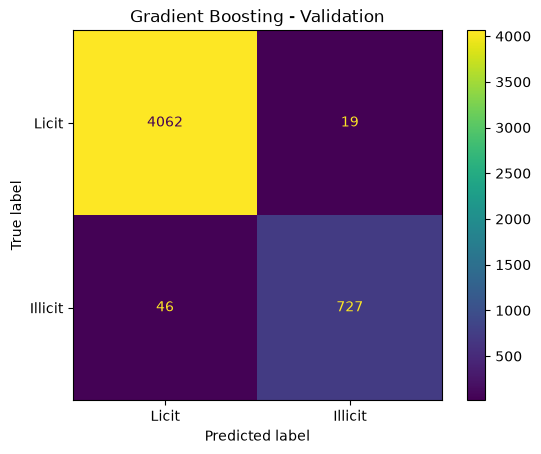

In [15]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

gb_pred = (gb_probs >= 0.5).astype(int)

print(classification_report(
    y_val,
    gb_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    gb_pred,
    display_labels=["Licit", "Illicit"]
)

plt.title("Gradient Boosting - Validation")
plt.show()

In [16]:
# Compare with random forest
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "ROC-AUC": [
        0.9269,
        roc_auc_score(y_val, rf_probs),
        roc_auc_score(y_val, gb_probs)
    ],
    "PR-AUC": [
        0.6546,
        average_precision_score(y_val, rf_probs),
        average_precision_score(y_val, gb_probs)
    ]
})

display(comparison)

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.926900,0.654600
1,Random Forest,0.995239,0.987603
2,Gradient Boosting,0.997159,0.988568


In [17]:
# Walk-forward validation for gradient boosting
from sklearn.base import clone

folds = [
    (19, 20, 24),
    (24, 25, 29),
    (29, 30, 35)
]

gb_results = []

for train_end, val_start, val_end in folds:

    fold_train = labelled[
        labelled["time_step"] <= train_end
    ]

    fold_val = labelled[
        labelled["time_step"].between(
            val_start, val_end
        )
    ]

    X_fold_train = fold_train[feature_cols]
    y_fold_train = fold_train[TARGET].astype(int)

    X_fold_val = fold_val[feature_cols]
    y_fold_val = fold_val[TARGET].astype(int)

    model = clone(gb_pipeline)

    model.fit(X_fold_train, y_fold_train)

    probs = model.predict_proba(X_fold_val)[:, 1]

    gb_results.append({
        "train_end": train_end,
        "validation": f"{val_start}-{val_end}",
        "roc_auc": roc_auc_score(y_fold_val, probs),
        "average_precision": average_precision_score(
            y_fold_val, probs
        ),
        "illicit_rate": y_fold_val.mean()
    })

gb_cv_results = pd.DataFrame(gb_results)

display(gb_cv_results)

print(
    "Mean ROC-AUC:",
    gb_cv_results["roc_auc"].mean()
)

print(
    "Mean PR-AUC:",
    gb_cv_results["average_precision"].mean()
)

,train_end,validation,roc_auc,average_precision,illicit_rate
0,19,20-24,0.952049,0.880880,0.126046
1,24,25-29,0.997044,0.991189,0.234955
2,29,30-35,0.997159,0.988568,0.159250


Mean ROC-AUC: 0.9820840710901199
Mean PR-AUC: 0.9535455599865168


In [18]:
# Compare walk-forward results
comparison_cv = pd.DataFrame({
    "Validation": cv_results["validation"],
    "RF ROC-AUC": cv_results["roc_auc"],
    "GB ROC-AUC": gb_cv_results["roc_auc"],
    "RF PR-AUC": cv_results["average_precision"],
    "GB PR-AUC": gb_cv_results["average_precision"]
})

display(comparison_cv)

,Validation,RF ROC-AUC,GB ROC-AUC,RF PR-AUC,GB PR-AUC
0,20-24,0.890128,0.952049,0.845679,0.880880
1,25-29,0.995867,0.997044,0.989227,0.991189
2,30-35,0.995239,0.997159,0.987603,0.988568


### Gradient boosting results

Gradient boosting achieved 0.9972 ROC-AUC and 0.9886 average precision on steps 30–35, slightly ahead of the random forest. At a 0.5 threshold, it identified 727 of 773 illicit transactions, with 19 false positives and 46 false negatives.

It also performed better than the random forest in all three walk-forward windows. The largest gain was on steps 20–24, where ROC-AUC rose from 0.8901 to 0.9520. The variation between windows remains important when selecting a model for future transactions.

## Checking for data leakage

The following checks inspect the selected features, exact duplicate feature rows across the train/validation boundary, and the effect of removing or isolating an influential feature.

In [19]:
print("Number of features:", len(X_train.columns))
print("\nFeatures used for training:")
print(X_train.columns.tolist())

print("\nPotentially suspicious columns:")
suspicious = [
    col for col in X_train.columns
    if any(term in col.lower() for term in [
        "label", "target", "fraud", "illicit",
        "class", "prediction", "score", "time", "id"
    ])
]

print(suspicious)

Number of features: 165

Features used for training:
['feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6', 'feat_7', 'feat_8', 'feat_9', 'feat_10', 'feat_11', 'feat_12', 'feat_13', 'feat_14', 'feat_15', 'feat_16', 'feat_17', 'feat_18', 'feat_19', 'feat_20', 'feat_21', 'feat_22', 'feat_23', 'feat_24', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_33', 'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_41', 'feat_42', 'feat_43', 'feat_44', 'feat_45', 'feat_46', 'feat_47', 'feat_48', 'feat_49', 'feat_50', 'feat_51', 'feat_52', 'feat_53', 'feat_54', 'feat_55', 'feat_56', 'feat_57', 'feat_58', 'feat_59', 'feat_60', 'feat_61', 'feat_62', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_70', 'feat_71', 'feat_72', 'feat_73', 'feat_74', 'feat_75', 'feat_76', 'feat_77', 'feat_78', 'feat_79', 'feat_80', 'feat_81', 'feat_82', 'feat_83', 'feat_84', 'feat_85', 'feat_86', 'feat_87'

In [20]:
# Check for duplicate feature rows
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

val_hashes = pd.util.hash_pandas_object(
    X_val, index=False
)

overlap = val_hashes.isin(set(train_hashes))

print("Identical feature rows:", overlap.sum())
print("Percentage of validation rows duplicated:",
      f"{overlap.mean():.2%}")

Identical feature rows: 0
Percentage of validation rows duplicated: 0.00%


In [21]:
# Check whether a small set of features drives performance
from sklearn.inspection import permutation_importance

result = permutation_importance(
    gb_pipeline,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

,feature,importance
52,feat_53,0.065280
46,feat_47,0.011511
58,feat_59,0.009491
60,feat_61,0.008015
75,feat_76,0.007835
45,feat_46,0.006060
162,feat_163,0.004756
89,feat_90,0.004311
66,feat_67,0.003121
2,feat_3,0.002981


In [22]:
# Remove the most influential feature and retrain
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score

# Remove feat_53 from both datasets
X_train_ablation = X_train.drop(columns=["feat_53"])
X_val_ablation = X_val.drop(columns=["feat_53"])

# Create a fresh copy of Gradient Boosting
gb_ablation = clone(gb_pipeline)

# Retrain without feat_53
gb_ablation.fit(X_train_ablation, y_train)

# Predict
ablation_probs = gb_ablation.predict_proba(X_val_ablation)[:, 1]

# Compare
ablation_results = pd.DataFrame({
    "Model": [
        "Original Gradient Boosting",
        "Without feat_53"
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, gb_probs),
        roc_auc_score(y_val, ablation_probs)
    ],
    "PR-AUC": [
        average_precision_score(y_val, gb_probs),
        average_precision_score(y_val, ablation_probs)
    ]
})

display(ablation_results)

,Model,ROC-AUC,PR-AUC
0,Original Gradient Boosting,0.997159,0.988568
1,Without feat_53,0.996543,0.984916


In [23]:
#training on only feature 53
gb_single = clone(gb_pipeline)

gb_single.fit(
    X_train[["feat_53"]],
    y_train
)

single_probs = gb_single.predict_proba(
    X_val[["feat_53"]]
)[:, 1]

print("feat_53 only ROC-AUC:",
      roc_auc_score(y_val, single_probs))

print("feat_53 only PR-AUC:",
      average_precision_score(y_val, single_probs))

feat_53 only ROC-AUC: 0.9396136705199657
feat_53 only PR-AUC: 0.7242992762384093


### Leakage checks

The feature list contained no obvious target or identifier columns, and the checks found no identical feature rows or overlapping transaction IDs between the training and validation sets.

Removing `feat_53` reduced ROC-AUC from 0.9972 to 0.9965 and average precision from 0.9886 to 0.9849. Training on `feat_53` alone gave 0.9396 ROC-AUC and 0.7243 average precision. The strong result is therefore not explained by that feature alone.

These checks do not rule out leakage introduced during the construction of anonymised features; that information is not available in the notebook.